# Pre-entrega 14 · Análisis visual de distribuciones categóricas y outliers

**Data Science II — EDA reproducible | Caso: cuentas y propinas en un restaurante**

> **Pregunta de análisis:** ¿Cómo se distribuyen los consumos y las propinas entre días de la semana y qué registros extremos merecen revisión antes de entrenar un modelo?

**Checklist:** inspección y limpieza justificada → barplot → boxplot → violin plot → asimetría y curtosis → IQR → segmentación → decisión de negocio.

**Fuente:** copia local del dataset real `tips`, disponible en `plotly.express.data.tips()` y en el repositorio público `mwaskom/seaborn-data`. Original: https://github.com/mwaskom/seaborn-data/blob/master/tips.csv. La muestra contiene 244 observaciones históricas y 7 variables; **no es representativa de todos los restaurantes**.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

raices = [Path.cwd(), Path.cwd().parent]
ROOT = next((ruta for ruta in raices if (ruta / "datos" / "tips.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ejecutá el notebook desde la raíz o desde notebooks/ del proyecto")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.eda import cargar_datos, resumen_descriptivo, marcar_iqr

(ROOT / "graficos").mkdir(exist_ok=True)
(ROOT / "resultados").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (9.2, 5.2), "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /mnt/data/build_pe14/dsii-preentrega-14-distribuciones-outliers


## 1. Carga y exploración inicial

Se inspeccionan los tipos, los nulos y los registros repetidos **antes** de aplicar transformaciones. `registro_ref` es un ID auxiliar agregado por nosotros. Dos filas con el mismo contenido no implican necesariamente el mismo consumo si el dataset no tiene ID transaccional: no las borramos por defecto.

In [2]:
df = cargar_datos(ROOT / "datos" / "tips.csv")
print("Dimensiones:", df.shape, "(incluye registro_ref sintético)")
print("Nulos:", int(df.isna().sum().sum()))
print("Filas con contenidos idénticos (sin registro_ref):", int(df.drop(columns='registro_ref').duplicated().sum()))
print("Tipos de dato:")
print(df.dtypes.to_string())
display(df.head(7))

Dimensiones: (244, 8) (incluye registro_ref sintético)
Nulos: 0
Filas con contenidos idénticos (sin registro_ref): 1
Tipos de dato:
registro_ref       int64
total_bill       float64
tip              float64
sex             category
smoker          category
day             category
time            category
size               int64


,registro_ref,total_bill,tip,sex,smoker,day,time,size
0,1,16.99,1.01,Female,No,Sun,Dinner,2
1,2,10.34,1.66,Male,No,Sun,Dinner,3
2,3,21.01,3.50,Male,No,Sun,Dinner,3
3,4,23.68,3.31,Male,No,Sun,Dinner,2
4,5,24.59,3.61,Female,No,Sun,Dinner,4
5,6,25.29,4.71,Male,No,Sun,Dinner,4
6,7,8.77,2.00,Male,No,Sun,Dinner,2


## 2. Variables categóricas — Barplot

El gráfico de barras muestra la cantidad **observada** de registros por día. No es una comparación de ventas diarias normalizadas por cantidad de días relevados.

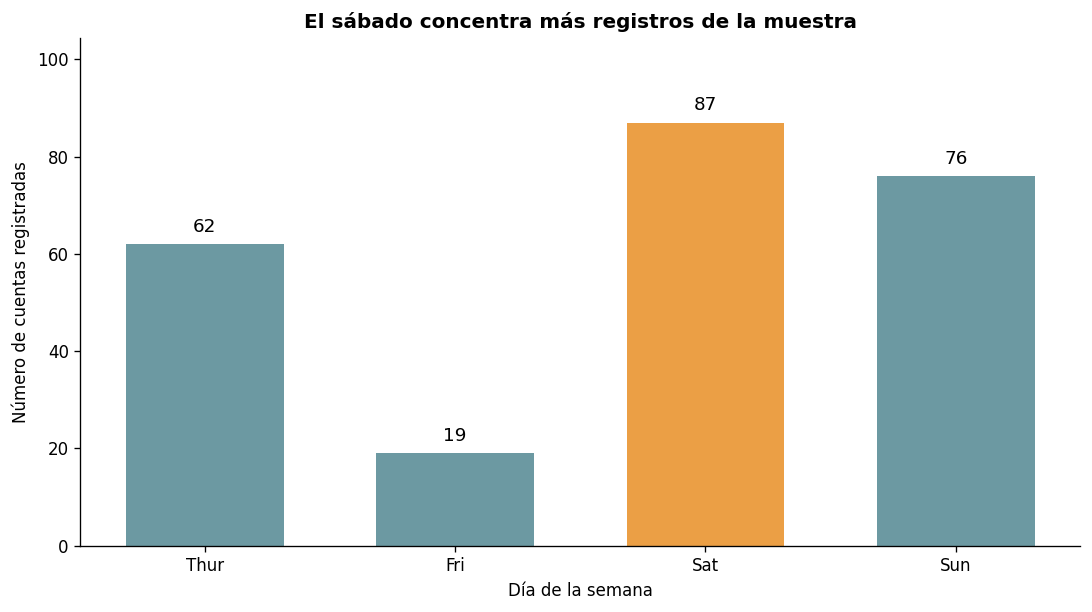

Frecuencias observadas: {'Thur': 62, 'Fri': 19, 'Sat': 87, 'Sun': 76}


In [3]:
orden = ['Thur','Fri','Sat','Sun']
conteos = df['day'].value_counts().reindex(orden, fill_value=0)
fig, ax = plt.subplots()
bar = ax.bar(orden, conteos.values, color=['#6c99a2','#6c99a2','#eb9f45','#6c99a2'], width=0.63)
ax.bar_label(bar, padding=5, fontsize=11)
ax.set(title='El sábado concentra más registros de la muestra', xlabel='Día de la semana', ylabel='Número de cuentas registradas')
ax.set_ylim(0, max(conteos.values) * 1.20)
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '01_barras_por_dia.png', dpi=175, bbox_inches='tight')
plt.show()
print('Frecuencias observadas:', conteos.to_dict())

## 3. Distribución del importe — Boxplot

El **boxplot** indica mediana, cuartiles y puntos que quedan fuera de los bigotes de la regla habitual de 1,5 × IQR **calculada por cada día** por Seaborn. Esos puntos no son necesariamente errores. **Atención:** más adelante el IQR para segmentar registros será **global**, y sus resultados pueden diferir del boxplot agrupado.

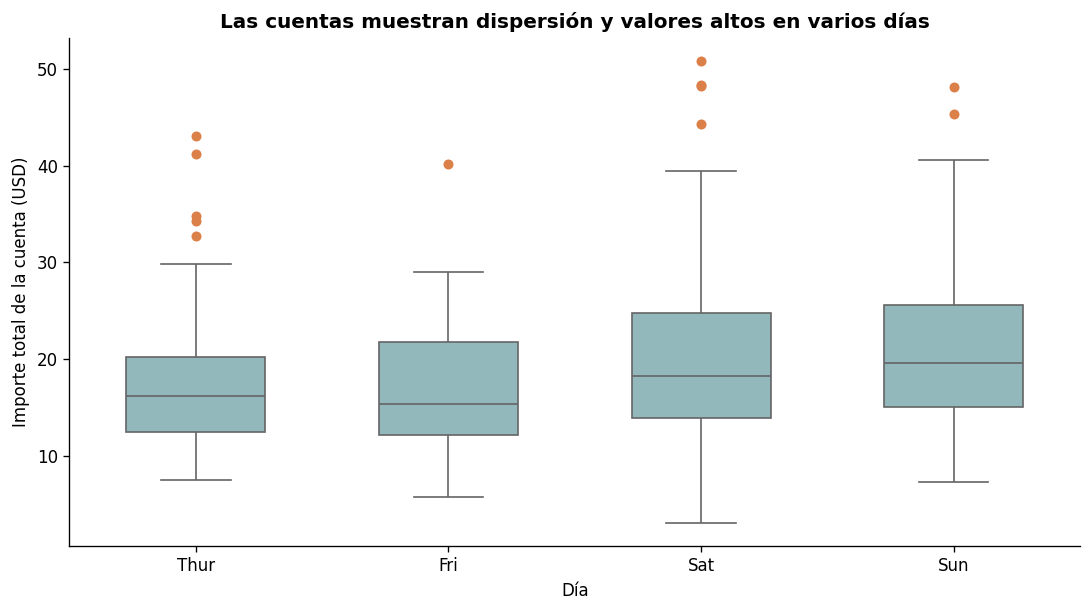

In [4]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x='day', y='total_bill', order=orden, color='#8cbdc3', ax=ax, width=.55, flierprops={'marker':'o','markersize':5,'markerfacecolor':'#dc8049','markeredgecolor':'#dc8049'})
ax.set(title='Las cuentas muestran dispersión y valores altos en varios días', xlabel='Día', ylabel='Importe total de la cuenta (USD)')
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '02_boxplot_importe_por_dia.png',dpi=175,bbox_inches='tight')
plt.show()

## 4. Forma y densidad — Violin Plot

El **violin plot** permite ver asimetrías, dispersión y concentración de propinas por día. La envolvente es una **estimación suavizada de densidad**, no son más registros; se limita a la amplitud de los datos (`cut=0`). Sus cuartiles internos favorecen la comparación.

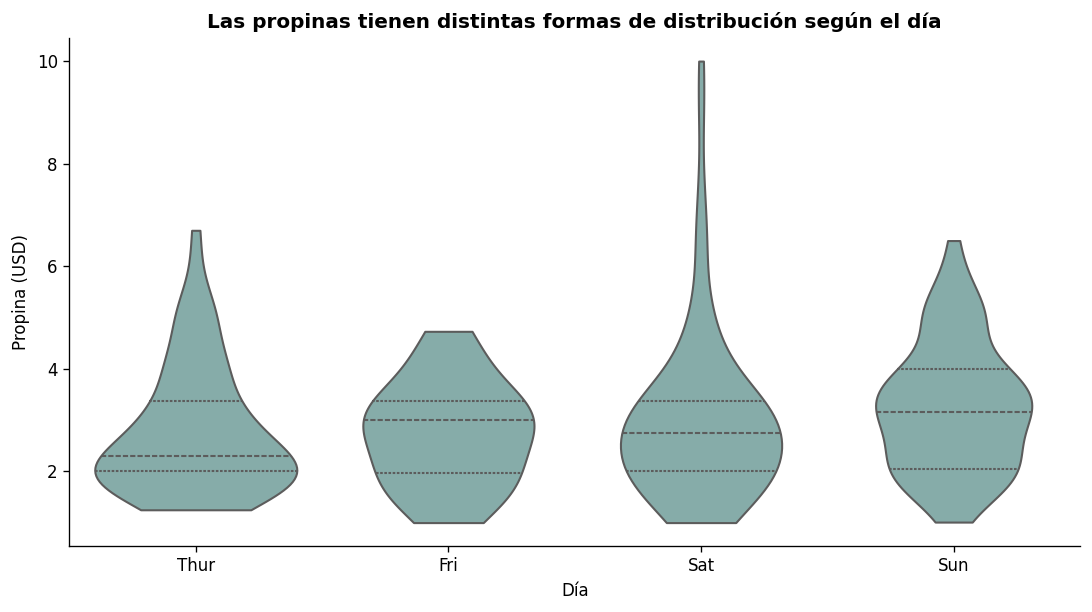

In [5]:
fig, ax = plt.subplots()
sns.violinplot(data=df, x='day', y='tip', order=orden, color='#7fb3ae', inner='quart', cut=0, ax=ax)
ax.set(title='Las propinas tienen distintas formas de distribución según el día', xlabel='Día', ylabel='Propina (USD)')
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '03_violin_propina_por_dia.png',dpi=175,bbox_inches='tight')
plt.show()

## 5. Tendencia central, dispersión, asimetría y curtosis

Calculamos explícitamente media, mediana, desviación estándar, cuartiles, **skewness** (`pandas.Series.skew()`) y **curtosis en exceso** (`pandas.Series.kurt()`, convención de Fisher: referencia normal = 0). Una asimetría positiva indica cola a la **derecha**. Valores de curtosis positivos sugieren colas más pesadas que la normal, sin justificar por sí solos quitar registros.

In [6]:
estadisticas = resumen_descriptivo(df)
display(estadisticas.round(4))
estadisticas.to_csv(ROOT / 'resultados' / 'resumen_estadistico.csv', index=False, encoding='utf-8')
for variable in ('total_bill','tip'):
    fila = estadisticas.loc[estadisticas['variable'] == variable].iloc[0]
    print(f"{variable}: asimetría={fila['asimetria']:.3f}; curtosis en exceso={fila['curtosis_exceso']:.3f}")

,variable,n,media,mediana,desviacion_std,minimo,q1,q3,maximo,asimetria,curtosis_exceso
0,total_bill,244,19.7859,17.795,8.9024,3.07,13.3475,24.1275,50.81,1.1332,1.2185
1,tip,244,2.9983,2.900,1.3836,1.00,2.0000,3.5625,10.00,1.4655,3.6484
2,size,244,2.5697,2.000,0.9511,1.00,2.0000,3.0000,6.00,1.4479,1.7317


total_bill: asimetría=1.133; curtosis en exceso=1.218
tip: asimetría=1.465; curtosis en exceso=3.648


## 6. Detección cuantitativa IQR — límites y listado de outliers

**Fórmulas:** `IQR = Q3 − Q1`, `LI = Q1 − 1,5 × IQR`, `LS = Q3 + 1,5 × IQR`. Es outlier un valor **estrictamente menor que LI o mayor que LS**. Las banderas se calculan sobre los importes de cuentas y propinas por separado, para evitar confundir una cuenta alta con una propina alta. Se calcula el umbral sobre la muestra completa porque esta actividad es exploratoria; para ML supervisado se ajustaría exclusivamente en train.

In [7]:
marcado, limites_cuenta = marcar_iqr(df, 'total_bill')
marcado, limites_propina = marcar_iqr(marcado, 'tip')
marcado['outlier_alguno'] = marcado['outlier_total_bill'] | marcado['outlier_tip']
marcado['outlier_ambos'] = marcado['outlier_total_bill'] & marcado['outlier_tip']
limites = pd.DataFrame([limites_cuenta, limites_propina])
display(limites.round(4))
print('Outliers en total_bill:', int(marcado['outlier_total_bill'].sum()))
print('Outliers en tip:', int(marcado['outlier_tip'].sum()))
print('Outliers distintos:', int(marcado['outlier_alguno'].sum()))
print('Outliers simultáneos:', int(marcado['outlier_ambos'].sum()))
columnas = ['registro_ref','day','time','size','total_bill','tip','outlier_total_bill','outlier_tip']
outliers = marcado.loc[marcado['outlier_alguno'], columnas].sort_values(['total_bill','tip'], ascending=False)
display(outliers)
outliers.to_csv(ROOT / 'resultados' / 'outliers_iqr.csv', index=False, encoding='utf-8')

,variable,q1,q3,iqr,limite_inferior,limite_superior,n_atipicos,factor
0,total_bill,13.3475,24.1275,10.7800,-2.8225,40.2975,9,1.5
1,tip,2.0000,3.5625,1.5625,-0.3438,5.9062,9,1.5


Outliers en total_bill: 9
Outliers en tip: 9
Outliers distintos: 15
Outliers simultáneos: 3


,registro_ref,day,time,size,total_bill,tip,outlier_total_bill,outlier_tip
170,171,Sat,Dinner,3,50.81,10.00,True,True
212,213,Sat,Dinner,4,48.33,9.00,True,True
59,60,Sat,Dinner,4,48.27,6.73,True,True
156,157,Sun,Dinner,6,48.17,5.00,True,False
182,183,Sun,Dinner,3,45.35,3.50,True,False
102,103,Sat,Dinner,3,44.30,2.50,True,False
197,198,Thur,Lunch,4,43.11,5.00,True,False
142,143,Thur,Lunch,5,41.19,5.00,True,False
184,185,Sun,Dinner,2,40.55,3.00,True,False
23,24,Sat,Dinner,4,39.42,7.58,False,True


## 7. Evidencia visual del criterio numérico — histogramas y límites

Aquí el límite superior **global** sí coincide con la clasificación del apartado anterior. No hay outliers inferiores en estas variables. El histograma sirve para comprobar visualmente la cola derecha y el umbral; el `binning` no afecta las banderas IQR.

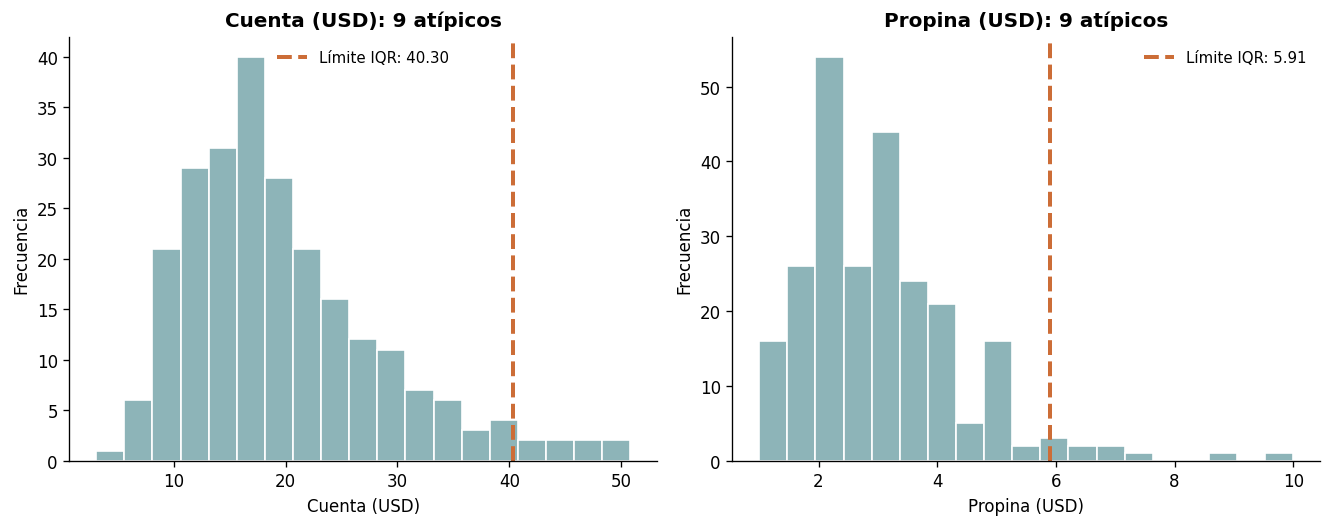

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2,4.5))
for ax, variable, detalle, etiqueta in zip(axes,['total_bill','tip'],[limites_cuenta,limites_propina],['Cuenta (USD)','Propina (USD)']):
    ax.hist(df[variable], bins=19, color='#8db4b8', edgecolor='white')
    ax.axvline(detalle['limite_superior'], color='#cc6d37', linewidth=2.4, linestyle='--', label=f"Límite IQR: {detalle['limite_superior']:.2f}")
    ax.set(title=f"{etiqueta}: {detalle['n_atipicos']} atípicos", xlabel=etiqueta, ylabel='Frecuencia')
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(ROOT/'graficos'/'04_histogramas_limites_iqr.png', dpi=175, bbox_inches='tight')
plt.show()

## 8. Decisión para negocio y para un futuro pipeline ML

**Conclusiones observadas.** En la muestra, el sábado concentra 87 de las 244 cuentas; tanto `total_bill` como `tip` muestran cola hacia la derecha. Usando IQR global, se señalan **9** cuentas altas y **9** propinas altas, con **3** registros coincidentes; en total son **15 observaciones distintas** (aprox. **6,15 %**). Esto no significa fraude ni registros equivocados.

**Decisión:** **no eliminar automáticamente los outliers**. Primero revisar si su importe es coherente con el tamaño de la mesa, si hay errores de captura y si existe evidencia operativa. Los registros extremos pueden ser consumos genuinos y aportan información. Ante un modelo sensible a valores extremos, comparar conservación con escalado robusto o `log1p` aplicado dentro de un pipeline, medido fuera de muestra. Los límites de decisión deben calcularse solo en entrenamiento para evitar **data leakage**.

**Limitaciones:** dataset histórico de un solo restaurante, no representativo; sin identificador transaccional (una coincidencia de todos los campos no permite deduplicar con seguridad); asociación no significa causalidad; cuartiles/IQR del boxplot por día no son lo mismo que el IQR global documentado.

In [9]:
assert len(df) == 244
assert df[['total_bill','tip']].notna().all().all()
assert int(marcado['outlier_total_bill'].sum()) == 9
assert int(marcado['outlier_tip'].sum()) == 9
assert int(marcado['outlier_alguno'].sum()) == 15
assert int(marcado['outlier_ambos'].sum()) == 3
print('VALIDACIONES FINALES: OK | gráficos guardados | tablas de resultados exportadas')

VALIDACIONES FINALES: OK | gráficos guardados | tablas de resultados exportadas
